In [1]:
from jhr.codes.espresso.io import QEOutParser
prs = QEOutParser('pw.x')
file = '/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/study/scf.out'
file = '/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/linking/relax.out'
df = prs.outparser.Process(file)

/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/linking/relax.out


In [3]:
from pymatgen.io.espresso.outputs import PWxml

file = '/home/fes33/Documents/Temp/scf.xml'
calc = PWxml(file)

/home/fes33/miniforge3/envs/py313mats/lib/python3.13/site-packages/pymatgen/io/espresso/outputs/pwxml.py:1093: UserWarning: Species labels contain numbers, which is common in AFM structures. This may cause problems with pymatgen's automatic oxidation state determination.
  warnings.warn(


## Defect Analysis (Test)

In [2]:
import sys
sys.path.append("/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/")


In [11]:
import warnings
from monty.serialization import loadfn
from pymatgen.analysis.defects.thermo import FormationEnergyDiagram
from pymatgen.io.vasp import Vasprun

warnings.filterwarnings("ignore")

from pathlib import Path

from pymatgen.analysis.defects.core import Substitution
from pymatgen.core import PeriodicSite, Species, Structure

TEST_FILES = Path("/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/tests/test_files")

gan_struct = Structure.from_file(TEST_FILES / "GaN.vasp")

# make a substitution site
ga_site = gan_struct[0]
mg_site = PeriodicSite(
    species=Species("Mg"), coords=ga_site.frac_coords, lattice=gan_struct.lattice
)

# instantiate the defect object
mg_ga = Substitution(structure=gan_struct, site=mg_site)

sc_dir = TEST_FILES / "Mg_Ga"
# ents = MPRester().get_entries_in_chemsys("Mg-Ga-N") # Query from MPRester
ents = loadfn(TEST_FILES / "Ga_Mg_N.json")  # Load from local

fed = FormationEnergyDiagram.with_directories(
    directory_map={
        "bulk": sc_dir / "bulk_sc",
        0: sc_dir / "q=0",
        -1: sc_dir / "q=-1",
        1: sc_dir / "q=1",
    },
    defect=mg_ga,
    pd_entries=ents,
    dielectric=10,
)

fed.as_dataframe()

,name,charge_state,bulk_total_energy,defect_total_energy,correction_freysoldt
0,Mg_Ga,0,None,-206.957934,0.000000
1,Mg_Ga,-1,None,-202.339260,0.405532
2,Mg_Ga,1,None,-211.383950,-0.090272


In [12]:


for i, p in enumerate(fed.chempot_limits):
    print(f"Limits for the chemical potential changes for point {i}")
    for k,v in p.items():
        print(f"Δμ_{k} = {v:.2f} eV")



Limits for the chemical potential changes for point 0
Δμ_Mg = -1.49 eV
Δμ_Ga = -1.75 eV
Δμ_N = 0.00 eV
Limits for the chemical potential changes for point 1
Δμ_Mg = -0.35 eV
Δμ_Ga = -0.03 eV
Δμ_N = -1.71 eV
Limits for the chemical potential changes for point 2
Δμ_Mg = -0.44 eV
Δμ_Ga = 0.00 eV
Δμ_N = -1.75 eV


<Axes: title={'center': 'Lattice Direction 3'}, xlabel='distance along axis ($\\AA$)', ylabel='Potential (V)'>

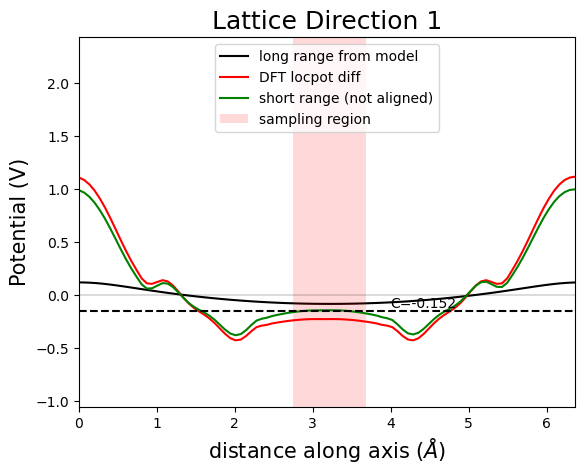

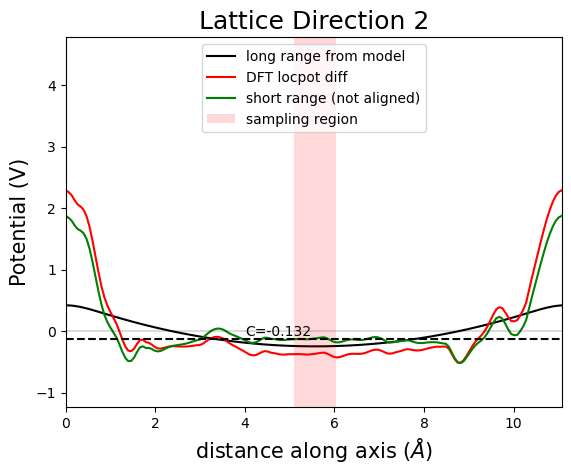

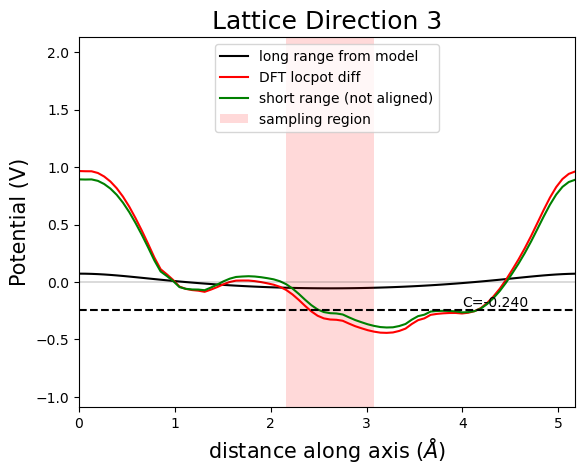

In [13]:


from pymatgen.analysis.defects.corrections.freysoldt import plot_plnr_avg
plot_data = fed.defect_entries[1].corrections_metadata["freysoldt"]["plot_data"]
plot_plnr_avg(plot_data[0], title="Lattice Direction 1")
plot_plnr_avg(plot_data[1], title="Lattice Direction 2")
plot_plnr_avg(plot_data[2], title="Lattice Direction 3")



## Defect Analysis

In [ ]:
import warnings
from monty.serialization import loadfn
from pymatgen.analysis.defects.thermo import FormationEnergyDiagram
from pymatgen.io.vasp import Vasprun

warnings.filterwarnings("ignore")

from pathlib import Path

from pymatgen.analysis.defects.core import Substitution
from pymatgen.core import PeriodicSite, Species, Structure

# TEST_FILES = Path("/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/src/pymatgen-analysis-defects/tests/test_files")

from pymatgen.io.espresso.outputs import PWxml
pristine_file = '/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/data/outfiles/xml/CsPbI3.xml'
pristine_calc = PWxml(pristine_file)

pristine_struct = pristine_calc.structures[0]
site_num = 8

# make a substitution site
defect_site = pristine_struct[site_num]
defect_periodic = PeriodicSite(
    species=Species("Zn"), 
    coords=defect_site.frac_coords, 
    lattice=pristine_struct.lattice
)

# instantiate the defect object
defect = Substitution(structure=pristine_struct, site=defect_periodic)

sc_dir = TEST_FILES / "Mg_Ga"
# ents = MPRester().get_entries_in_chemsys("Mg-Ga-N") # Query from MPRester
# ents = loadfn(TEST_FILES / "Ga_Mg_N.json")  # Load from local
ents = pristine_calc.get_computed_entry(entry_id = "")

fed = FormationEnergyDiagram.with_directories(
    directory_map={
        "bulk": sc_dir / "bulk_sc",
        0: sc_dir / "q=0",
        -1: sc_dir / "q=-1",
        1: sc_dir / "q=1",
    },
    defect=defect,
    pd_entries=ents,
    dielectric=25,
)

FormationEnergyDiagram(
    bulk_entry: 'ComputedStructureEntry',
    defect_entries: 'List[DefectEntry]',
    pd_entries=ents,
    vbm: 'float',
    band_gap: 'Optional[float]' = None,
    inc_inf_values: 'bool' = False,
)


In [29]:
struct = calc.structures[0]
type(struct.composition)

pymatgen.core.composition.Composition

In [32]:
import pymatgen_analysis_defects

ModuleNotFoundError: No module named 'pymatgen_analysis_defects'

In [5]:
dir(calc)

['REDIRECT',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__get_pydantic_core_schema__',
 '__get_pydantic_json_schema__',
 '__get_validators__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__modify_schema__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_filename',
 '_fudge_vasp_params',
 '_generic_json_schema',
 '_parse',
 '_parse_atominfo',
 '_parse_calculation',
 '_parse_chemical_shielding',
 '_parse_diel',
 '_parse_dos',
 '_parse_dynmat',
 '_parse_eigen',
 '_parse_ionic_step',
 '_parse_kpoints',
 '_parse_optical_transition',
 '_parse_params',
 '_parse_pdos',
 '_parse_projected_eigen',
 '_parse_relaxation',
 '_parse_structure',
 '_parse_vbm_cbm_efermi',
 '_raw_dict',
 '_set_pw_calc_p

## class

In [138]:
from jhr._helpers import Constants
class PWParse:
    """
    From: https://blog.levilentz.com/parse-quantum-espresso-output-file/

    Takes a pw.x output file and reads all the relevant values.

    Example:
      test = PWParse()
      test.Process("vc.out")

      print(test.to_JSON())


    """


    def __init__(self, file = None):
        self.file = file
        self.BOHRtoA = Constants.BOHRtoA
        self.RYtoeV = Constants.RYtoeV
    def Process(self, file_path = None):
        """
        Parses a passed file for standard parsing. Uses self.file if no file is passed. 
        """
        if file_path is None: file_path = self.file

        cols = ["value", "unit", "description"]
        self.data = pd.DataFrame(columns=cols)
        self.lattice = {"a": [0, 0, 0], "b": [0, 0, 0], "c": [0, 0, 0]}
        self.norms = {}
        self.angles = {}
        self.atoms = []
        
        print(file_path)
        f = open(file_path, "r")

        for linenum, i in enumerate(f):
            if linenum < 1000:
                if "number of k points=" in i:
                    val = 8
                    self.data.loc["kpoints"] = [val, "unitless", "Number of k-points in the Brillouin zone"]
                    continue
            if "End of self-consistent calculation" in i:
                bands = 8
                kpts = 74
                
                numlines = int(np.floor(bands / 8.0)) + 1

                bnddiagram = np.zeros((kpts, bands),dtype=float)
                counter = 0
                while counter < kpts:
                    line = next(f)
                    if "k =" in line:
                        line = next(f)
                        idx = 0
                        for _ in range(numlines):
                            line = next(f).split()
                            for val in line:
                                bnddiagram[counter][idx] = float(val)
                                idx += 1
                        counter += 1
                bnddiagram = np.random.rand(74,
                self.data.loc["bnddiagram"] = [bnddiagram, "N/A", "Band diagram"]
                continue

        f.close()
        return self.data


## code

In [150]:
pd.Series([bnddiagram, "N/A"])

0    [[0.9080852237365503, 0.1510479533426735, 0.45...
1                                                  N/A
dtype: object

In [151]:
cols = ["value", "unit", "description"]
df = pd.DataFrame(columns=cols).astype("object")

val = 8
df.loc["kpoints"] = [val, "unitless", "Number of k-points in the Brillouin zone"]
  
bnddiagram = np.random.rand(74,8)
# df.loc["bnddiagram"] = [bnddiagram, "N/A", "Band diagram"]
# df.loc["bnddiagram"] = [bnddiagram, "N/A", "Band diagram"]

df.loc["bnddiagram"] = pd.Series([bnddiagram, "N/A", "Band diagram"], index=cols)
df.loc["bnddiagram"] = pd.Series([bnddiagram, "N/A", "Band diagram"], index=cols)
df

,value,unit,description
kpoints,8,unitless,Number of k-points in the Brillouin zone
bnddiagram,"[[0.6206102820858156, 0.31759354092301484, 0.5...",N/A,Band diagram


In [139]:
prs = PWParse()
file_path = "/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/linking/relax.out"

prs.Process(file_path)

/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/scripts/linking/relax.out


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (3,) + inhomogeneous part.

In [97]:
prs.data.loc['program_version'][0]

/tmp/ipykernel_517773/1779703906.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  prs.data.loc['program_version'][0]


'v.6.7MaX'

In [111]:
import pandas as pd
df = pd.DataFrame(columns = ["Col A", "Col B", "Col C"])

df.loc["rowA"] = [1, "abc", "def"]
df.loc["rowB"] = [np.random.rand(4,4), "abc", "def"]


In [58]:
import re

txt = """        k(   10) = (  -0.5000000  -0.5000000  -0.5000000), wk =   0.0312500
k = 0.0000 0.0000 0.2 ( 55707 PWs)   bands (ev):
-18.1741 -18.1738 -18.1737 -18.1737 -18.1734 -18.1734 -18.1733 -18.1730
   -13.4577 -13.4558 -13.4513 -13.4503 -13.4499 -13.4486 -13.4372 -13.4352
   -13.3825 -13.3820 -13.3819 -13.3819 -13.3819 -13.3810 -13.3810 -13.3810
   -13.3810 -13.3810 -13.3810 -13.3810 -13.3769 -13.3769 -13.3769 -13.3350
   -13.3346 -13.3346 -13.3154 -13.3154 -13.3154 -13.2872 -13.2872 -13.2871"""
x = re.findall("k =.*:", txt) 

In [59]:
kpoints = []

for line in lines:
    if 'k =' in line and 'wk =' not in line:
        # Extract the first three floats after "k ="
        floats = re.findall(r'[-+]?\d*\.\d+|\d+', line)
        kpoints.append([float(f) for f in floats[:3]])

# Convert to numpy array
k_array = np.array(kpoints)

print(k_array)



In [61]:
import re
import numpy as np

with open('/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/data/outfiles/scf/pwscf.out', 'r') as f:
    lines = f.readlines()

def _find_kpoints(lines):
    
    kpoints = []

    for line in lines:
        if 'k =' in line and 'wk =' not in line:
            # Extract the first three floats after "k ="
            floats = re.findall(r'[-+]?\d*\.\d+|\d+', line)
            kpoints.append([float(f) for f in floats[:3]])
    k_array = np.array(kpoints)

# Convert to numpy array
k_array = _find_kpoints()
print(k_array)


[[ 0.    0.    0.  ]
 [ 0.    0.    0.25]
 [ 0.    0.   -0.5 ]
 [ 0.    0.25  0.25]
 [ 0.    0.25 -0.5 ]
 [ 0.   -0.5  -0.5 ]
 [ 0.25  0.25  0.25]
 [ 0.25  0.25 -0.5 ]
 [ 0.25 -0.5  -0.5 ]
 [-0.5  -0.5  -0.5 ]]


In [1]:
import numpy as np
import re

from jhr.codes.espresso.io import QEOutParser


file = "/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/jhr/data/outfiles/scf/pwscf.out"        

prs = QEOutParser('pw.x', file = file)
df = prs.parser.Process()
array_dict = prs.parser.band_occupancy()


occ =    array_dict['occupancy_array'] 
bands =    array_dict['bands_array'] 

occ = np.where(occ > 0.9, 1, 0)
bocc = bands*occ
bocc.max()




Found 10 occurrences of bands (ev)
Found 10 occurrences of occupation numbers


2.0427

In [2]:
df

,value,unit,description
program_version,v.7.4,N/A,Quantum ESPRESSO version
alat,12.455086,Å,Lattice parameter (alat)
volume,1932.149514,Å³,Unit cell volume
natoms,39,unitless,Number of atoms per unit cell
natypes,3,unitless,Number of atomic types
nelectrons,338.0,unitless,Number of electrons
bands,203,unitless,Number of Kohn-Sham states (bands)
ecut,544.227923,eV,Kinetic energy cutoff
rhocut,4353.823381,eV,Charge density cutoff
econvergence,0.0,unitless,Electronic convergence threshold


2.0427

In [ ]:
# Use argmax: it returns the first occurrence of True (i.e., 0)
first_zero_indices = zero_mask.argmax(axis=1)

# Handle rows with no zero (argmax will still return 0)
# So we need to mark those rows manually
has_zero = zero_mask.any(axis=1)
first_zero_indices[~has_zero] = -1  # or any other marker like 203

print(first_zero_indices)